# MÔ HÌNH 3: DBSCAN CLUSTERING (BASELINE TRÊN DỮ LIỆU SẠCH CƠ BẢN)
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)

Notebook này thực hiện huấn luyện và kiểm thử mô hình cơ sở (**Baseline**) phân cụm dựa trên mật độ DBSCAN (`eps=0.5`, `min_samples=10`) **trên tập dữ liệu giao dịch sạch cơ bản** (`data/train.csv`, `data/valid.csv`, `data/test.csv`) **chưa qua rút trích đặc trưng RFM**:
- **Dữ liệu đầu vào:** Tập dữ liệu giao dịch đã làm sạch sau giai đoạn EDA.
- **Thuộc tính cơ bản sử dụng:** `Quantity`, `Price`, `TotalPrice`.
- **Đặc trưng thuật toán:** Tự động phát hiện các cụm mật độ và tách lọc các điểm giao dịch cá biệt / dị biệt (Noise, nhãn `-1`).

In [1]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 Đường dẫn file nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy
📋 Đường dẫn file nhật ký thực nghiệm: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy\Experiment_Log_Comparison.csv


### 1. Nạp tập dữ liệu giao dịch sạch cơ bản (Train / Validation / Test)
Nạp dữ liệu từ các file `data/train.csv`, `data/valid.csv`, `data/test.csv`.

In [2]:
train_df = pd.read_csv("data/train.csv")
val_df = pd.read_csv("data/valid.csv")
test_df = pd.read_csv("data/test.csv")

print(f"📊 Tập Train:      {train_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Validation: {val_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Test:       {test_df.shape[0]:,} dòng giao dịch")

print("\n\n--- 5 Dòng dữ liệu giao dịch Train mẫu ---")
print(train_df[['CustomerID', 'Quantity', 'Price', 'TotalPrice', 'Country']].head())

📊 Tập Train:      251,501 dòng giao dịch
📊 Tập Validation: 72,685 dòng giao dịch
📊 Tập Test:       74,785 dòng giao dịch


--- 5 Dòng dữ liệu giao dịch Train mẫu ---
   CustomerID  Quantity  Price  TotalPrice         Country
0       13085        12   6.95        83.4  United Kingdom
1       13085        12   6.75        81.0  United Kingdom
2       13085        12   6.75        81.0  United Kingdom
3       13085        48   2.10       100.8  United Kingdom
4       13085        24   1.25        30.0  United Kingdom


### 2. Chuẩn hóa thang đo (StandardScaler) trên thuộc tính cơ bản
Sử dụng 3 thuộc tính: `['Quantity', 'Price', 'TotalPrice']`. Fit scaler duy nhất trên tập Train để chống rò rỉ dữ liệu.

In [3]:
features = ['Quantity', 'Price', 'TotalPrice']

X_train_raw = train_df[features]
X_val_raw = val_df[features]
X_test_raw = test_df[features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:")
print("   - Mean (Train):", scaler.mean_.round(3))
print("   - Scale/Std (Train):", scaler.scale_.round(3))

✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:
   - Mean (Train): [12.607  2.923 21.93 ]
   - Scale/Std (Train): [31.994  2.947 62.066]


### 3. Đồ thị $k$-distance (K-Nearest Neighbors) khảo sát bán kính $\epsilon$
Vẽ khoảng cách đến láng giềng thứ $k=10$ trên tập mẫu đại diện để quan sát điểm uốn xác định tham số $\epsilon$.

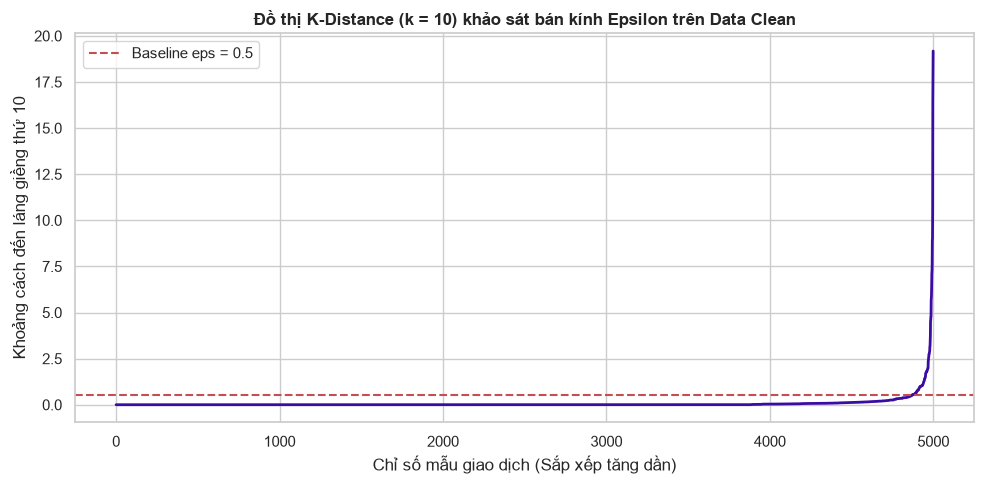

In [4]:
np.random.seed(42)
sample_size_kdist = min(5000, len(X_train_scaled))
kdist_idx = np.random.choice(len(X_train_scaled), size=sample_size_kdist, replace=False)
X_kdist_sample = X_train_scaled[kdist_idx]

k_neighbors = 10
nearest_neighbors = NearestNeighbors(n_neighbors=k_neighbors)
neighbors_fit = nearest_neighbors.fit(X_kdist_sample)
distances, indices = neighbors_fit.kneighbors(X_kdist_sample)

# Sắp xếp tăng dần
sorted_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(sorted_distances, color='#3a0ca3', lw=2)
plt.axhline(y=0.5, color='r', linestyle='--', label='Baseline eps = 0.5')
plt.title(f"Đồ thị K-Distance (k = {k_neighbors}) khảo sát bán kính Epsilon trên Data Clean", fontsize=12, fontweight='bold')
plt.xlabel("Chỉ số mẫu giao dịch (Sắp xếp tăng dần)")
plt.ylabel(f"Khoảng cách đến láng giềng thứ {k_neighbors}")
plt.legend()
plt.tight_layout()
plt.show()

### 4. Huấn luyện mô hình DBSCAN Baseline (`eps=0.5`, `min_samples=10`)
Sử dụng mẫu đại diện Train ($N=10,000$ mẫu giao dịch có kiểm soát `random_state=42`) để huấn luyện DBSCAN.

In [5]:
eps_baseline = 0.5
min_samples_baseline = 10

train_sample_size = min(10000, len(X_train_scaled))
np.random.seed(42)
train_sub_idx = np.random.choice(len(X_train_scaled), size=train_sample_size, replace=False)

X_train_sub = X_train_scaled[train_sub_idx]
train_df_sub = train_df.iloc[train_sub_idx].copy()

dbscan_baseline = DBSCAN(eps=eps_baseline, min_samples=min_samples_baseline)
train_labels = dbscan_baseline.fit_predict(X_train_sub)
train_df_sub['Cluster'] = train_labels

unique_labels = set(train_labels)
n_clusters = len(unique_labels - {-1})
n_noise = (train_labels == -1).sum()
noise_ratio = n_noise / len(train_labels) * 100

print(f"✅ Đã huấn luyện xong DBSCAN Baseline trên tập mẫu Train ({train_sample_size:,} mẫu)!")
print(f"   - Số cụm mật độ phát hiện được: {n_clusters}")
print(f"   - Số điểm nhiễu (Noise, nhãn -1): {n_noise:,} ({noise_ratio:.2f}%)")

✅ Đã huấn luyện xong DBSCAN Baseline trên tập mẫu Train (10,000 mẫu)!
   - Số cụm mật độ phát hiện được: 5
   - Số điểm nhiễu (Noise, nhãn -1): 171 (1.71%)


### 5. Kiểm thử trên tập Validation và Test (Nearest Core Sample)
Đối với các điểm mới trong Validation và Test, ta tìm khoảng cách đến Core Sample gần nhất của mô hình Train trong bán kính `eps=0.5`. Nếu nằm trong bán kính thì gán cụm tương ứng, ngược lại xem là điểm nhiễu ngoại lai (`-1`).

In [6]:
val_sample_size = min(5000, len(X_val_scaled))
test_sample_size = min(5000, len(X_test_scaled))

np.random.seed(42)
val_sub_idx = np.random.choice(len(X_val_scaled), size=val_sample_size, replace=False)
test_sub_idx = np.random.choice(len(X_test_scaled), size=test_sample_size, replace=False)

X_val_sub = X_val_scaled[val_sub_idx]
X_test_sub = X_test_scaled[test_sub_idx]

# Thuật toán gán nhãn cho tập mới dựa trên Core Samples
core_indices = dbscan_baseline.core_sample_indices_
core_samples = X_train_sub[core_indices]
core_labels = train_labels[core_indices]

nn_core = NearestNeighbors(n_neighbors=1).fit(core_samples)

def predict_dbscan(X_new):
    dists, indices = nn_core.kneighbors(X_new)
    labels = np.full(len(X_new), -1)
    within_eps = dists.ravel() <= eps_baseline
    labels[within_eps] = core_labels[indices.ravel()[within_eps]]
    return labels

val_labels = predict_dbscan(X_val_sub)
test_labels = predict_dbscan(X_test_sub)

# Hàm đánh giá an toàn trên các điểm không phải nhiễu
def evaluate_dbscan_metrics(X, labels):
    mask = labels != -1
    n_c = len(set(labels[mask]))
    if n_c > 1 and mask.sum() > 10:
        sil = silhouette_score(X[mask], labels[mask])
        db = davies_bouldin_score(X[mask], labels[mask])
        ch = calinski_harabasz_score(X[mask], labels[mask])
        return sil, db, ch
    return None, None, None

sil_train, db_train, ch_train = evaluate_dbscan_metrics(X_train_sub, train_labels)
sil_val, db_val, ch_val = evaluate_dbscan_metrics(X_val_sub, val_labels)
sil_test, db_test, ch_test = evaluate_dbscan_metrics(X_test_sub, test_labels)

print("=" * 70)
print(f"📊 BẢNG KẾT QUẢ ĐÁNH GIÁ DBSCAN BASELINE (eps={eps_baseline}, min_samples={min_samples_baseline}):")
print("=" * 70)
print(f"Tập Huấn luyện (Train):      Silhouette = {sil_train:.4f} | Davies-Bouldin = {db_train:.4f} | Calinski-Harabasz = {ch_train:,.2f}" if sil_train else "Train: Cần tinh chỉnh thêm")
print(f"Tập Kiểm định (Validation):  Silhouette = {sil_val:.4f} | Davies-Bouldin = {db_val:.4f} | Calinski-Harabasz = {ch_val:,.2f}" if sil_val else "Validation: Cần tinh chỉnh thêm")
print(f"Tập Kiểm thử (Test):         Silhouette = {sil_test:.4f} | Davies-Bouldin = {db_test:.4f} | Calinski-Harabasz = {ch_test:,.2f}" if sil_test else "Test: Cần tinh chỉnh thêm")
print("=" * 70)

📊 BẢNG KẾT QUẢ ĐÁNH GIÁ DBSCAN BASELINE (eps=0.5, min_samples=10):
Tập Huấn luyện (Train):      Silhouette = 0.6440 | Davies-Bouldin = 0.3666 | Calinski-Harabasz = 963.99
Tập Kiểm định (Validation):  Silhouette = 0.6353 | Davies-Bouldin = 0.3173 | Calinski-Harabasz = 297.90
Tập Kiểm thử (Test):         Silhouette = 0.6568 | Davies-Bouldin = 0.3796 | Calinski-Harabasz = 438.36


### 6. Phân tích chân dung các cụm và nhóm nhiễu (Cluster Profiling)

In [7]:
profile = train_df_sub.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Quantity': 'mean',
    'Price': 'mean',
    'TotalPrice': 'mean'
}).rename(columns={'CustomerID': 'SoLuong_BanGhi'})

profile['TyLe_%'] = (profile['SoLuong_BanGhi'] / len(train_df_sub) * 100).round(2)
profile['Quantity'] = profile['Quantity'].round(2)
profile['Price'] = profile['Price'].round(2)
profile['TotalPrice'] = profile['TotalPrice'].round(2)

print("--- THỐNG KÊ ĐẶC TRƯNG CỤM VÀ NHIỄU (DBSCAN TRAIN TRÊN DATA CLEAN) ---")
print(profile[['SoLuong_BanGhi', 'TyLe_%', 'Quantity', 'Price', 'TotalPrice']])

--- THỐNG KÊ ĐẶC TRƯNG CỤM VÀ NHIỄU (DBSCAN TRAIN TRÊN DATA CLEAN) ---
         SoLuong_BanGhi  TyLe_%  Quantity  Price  TotalPrice
Cluster                                                     
-1                  171    1.71    164.29   6.16      297.15
 0                 9617   96.17      9.62   2.66       16.53
 1                  128    1.28      2.12  12.75       27.09
 2                   60    0.60      1.47  15.70       22.96
 3                   13    0.13    146.15   0.58       85.42
 4                   11    0.11    153.09   1.60      244.61


### 7. Đánh giá thuộc tính nào đóng góp nhiều nhất vào việc phân cụm
Để biết mô hình DBSCAN gom cụm dựa trên thuộc tính nào nhiều nhất, chúng ta tính toán:
1. **Tọa độ trung bình các cụm (Cluster Means):** Thống kê giá trị trung bình của từng thuộc tính trên không gian chuẩn hóa Z-score giữa các cụm mật độ và nhóm điểm nhiễu (Noise).
2. **Kiểm định ANOVA F-Score (`f_classif`):** Đo mức độ phân biệt giữa các cụm mật độ hợp lệ (không kể nhiễu) để tính tỷ lệ % đóng góp của từng thuộc tính.

📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT (DBSCAN):
   Thuộc tính  Độ phân tách tâm cụm (Std)  ANOVA F-Score  Tỷ lệ đóng góp (%)
0       Price                      2.1311        1176.69               53.11
1    Quantity                      2.2265         662.78               29.91
2  TotalPrice                      1.3898         376.14               16.98
👉 KẾT LUẬN: Mô hình DBSCAN gom cụm dựa trên thuộc tính [Price] nhiều nhất (53.11%).


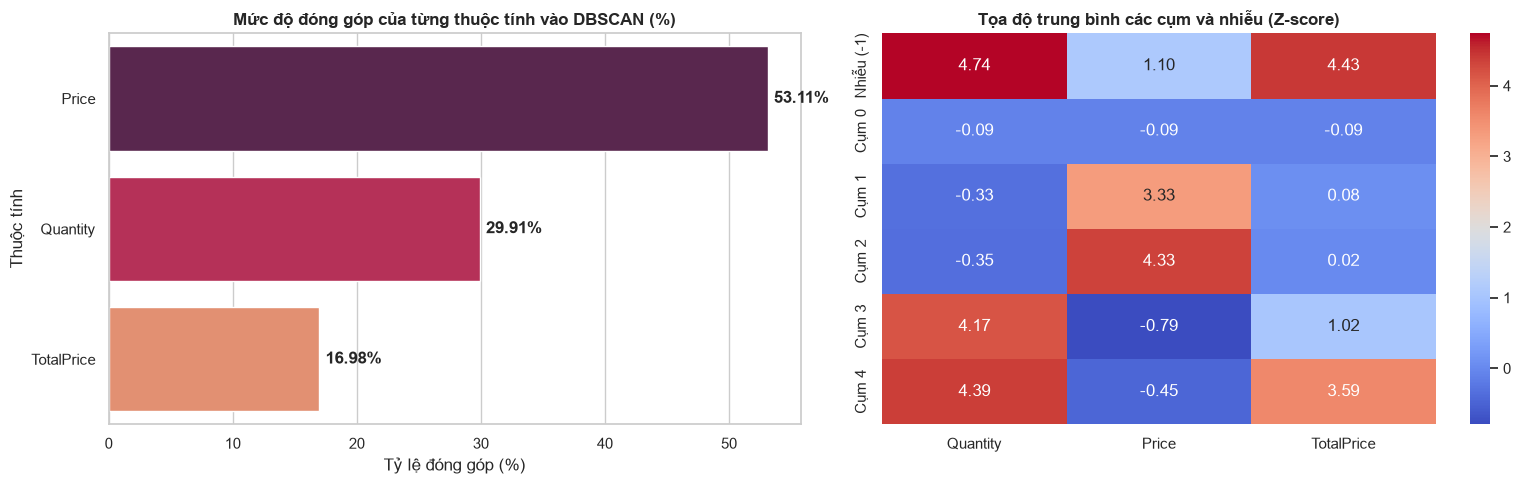

In [8]:
from sklearn.feature_selection import f_classif

# 1. Tính toán tọa độ trung bình theo từng cụm (kèm nhóm nhiễu -1)
cluster_means = []
cluster_names = []
for c in sorted(unique_labels):
    mask_c = (train_labels == c)
    cluster_means.append(X_train_sub[mask_c].mean(axis=0))
    cluster_names.append(f"Cụm {c}" if c != -1 else "Nhiễu (-1)")

df_centers = pd.DataFrame(cluster_means, columns=features, index=cluster_names)

# 2. Tính độ lệch chuẩn giữa các tâm cụm hợp lệ
valid_centers = [m for c, m in zip(sorted(unique_labels), cluster_means) if c != -1]
centroid_std = np.std(valid_centers, axis=0) if len(valid_centers) > 1 else np.zeros(len(features))

# 3. Tính ANOVA F-Score trên các mẫu hợp lệ (loại bỏ nhiễu)
valid_mask = (train_labels != -1)
if len(set(train_labels[valid_mask])) > 1:
    f_scores, p_values = f_classif(X_train_sub[valid_mask], train_labels[valid_mask])
else:
    f_scores, p_values = f_classif(X_train_sub, train_labels)

feature_importance = (f_scores / f_scores.sum()) * 100

# 4. Tổng hợp bảng xếp hạng mức độ ảnh hưởng của các thuộc tính
ranking_df = pd.DataFrame({
    'Thuộc tính': features,
    'Độ phân tách tâm cụm (Std)': centroid_std.round(4),
    'ANOVA F-Score': f_scores.round(2),
    'Tỷ lệ đóng góp (%)': feature_importance.round(2)
}).sort_values(by='Tỷ lệ đóng góp (%)', ascending=False).reset_index(drop=True)

print("=" * 65)
print("📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT (DBSCAN):")
print("=" * 65)
print(ranking_df)
print("=" * 65)

top_feature = ranking_df.iloc[0]['Thuộc tính']
top_percent = ranking_df.iloc[0]['Tỷ lệ đóng góp (%)']
print(f"👉 KẾT LUẬN: Mô hình DBSCAN gom cụm dựa trên thuộc tính [{top_feature}] nhiều nhất ({top_percent}%).")

# 5. Trực quan hóa mức độ đóng góp và tọa độ các cụm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ thanh tỷ lệ đóng góp
sns.barplot(data=ranking_df, x='Tỷ lệ đóng góp (%)', y='Thuộc tính', palette='rocket', ax=ax1)
ax1.set_title("Mức độ đóng góp của từng thuộc tính vào DBSCAN (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tỷ lệ đóng góp (%)")
for i, v in enumerate(ranking_df['Tỷ lệ đóng góp (%)']):
    ax1.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

# Biểu đồ Heatmap tọa độ tâm các cụm và nhóm nhiễu (Z-score)
sns.heatmap(df_centers, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2, cbar=True)
ax2.set_title("Tọa độ trung bình các cụm và nhiễu (Z-score)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 8. Trực quan hóa phân cụm (2D PCA Visualization)


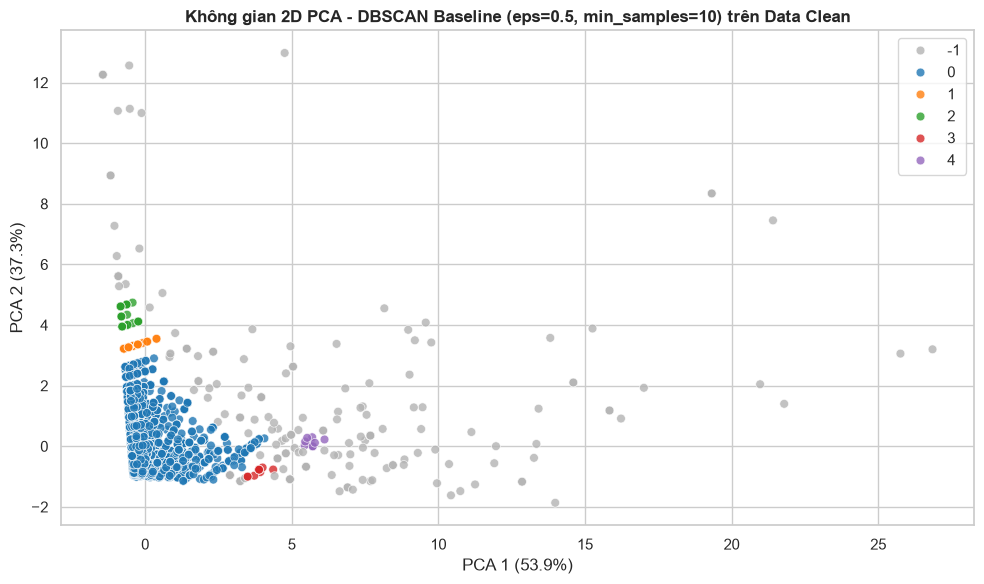

In [9]:
pca = PCA(n_components=2, random_state=42)
X_sub_pca = pca.fit_transform(X_train_sub)

plt.figure(figsize=(10, 6))

palette = sns.color_palette("tab10", n_colors=max(n_clusters, 1))
cluster_colors = {c: palette[c % len(palette)] for c in range(n_clusters)}
cluster_colors[-1] = (0.7, 0.7, 0.7, 0.4) # Màu xám mờ cho Noise

sns.scatterplot(
    x=X_sub_pca[:, 0], y=X_sub_pca[:, 1], hue=train_labels,
    palette=cluster_colors, s=40, alpha=0.8
)
plt.title(f"Không gian 2D PCA - DBSCAN Baseline (eps={eps_baseline}, min_samples={min_samples_baseline}) trên Data Clean", fontsize=12, fontweight='bold')
plt.xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout()
plt.show()

### 9. Ghi nhận kết quả vào nhật ký thực nghiệm `Experiment_Log_Comparison.csv`


In [10]:
now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

entries = [
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN Baseline (eps={eps_baseline}, min_samples={min_samples_baseline}, Data Clean) - Train",
        'Silhouette': round(sil_train, 4) if sil_train is not None else "N/A",
        'Davies-Bouldin': round(db_train, 4) if db_train is not None else "N/A",
        'Calinski-Harabasz': round(ch_train, 2) if ch_train is not None else "N/A"
    },
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN Baseline (eps={eps_baseline}, min_samples={min_samples_baseline}, Data Clean) - Validation",
        'Silhouette': round(sil_val, 4) if sil_val is not None else "N/A",
        'Davies-Bouldin': round(db_val, 4) if db_val is not None else "N/A",
        'Calinski-Harabasz': round(ch_val, 2) if ch_val is not None else "N/A"
    },
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN Baseline (eps={eps_baseline}, min_samples={min_samples_baseline}, Data Clean) - Test",
        'Silhouette': round(sil_test, 4) if sil_test is not None else "N/A",
        'Davies-Bouldin': round(db_test, 4) if db_test is not None else "N/A",
        'Calinski-Harabasz': round(ch_test, 2) if ch_test is not None else "N/A"
    }
]

df_entries = pd.DataFrame(entries)

if not os.path.exists(PATH_EXPERIMENT_LOG):
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='w')
else:
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='a', header=False)

print(f"💾 Đã lưu thành công 3 kết quả thực nghiệm vào: {PATH_EXPERIMENT_LOG}")
print(df_entries)

💾 Đã lưu thành công 3 kết quả thực nghiệm vào: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy\Experiment_Log_Comparison.csv
             Timestamp                                              Model  \
0  2026-11-23 14:24:18  DBSCAN Baseline (eps=0.5, min_samples=10, Data...   
1  2026-11-23 14:24:18  DBSCAN Baseline (eps=0.5, min_samples=10, Data...   
2  2026-11-23 14:24:18  DBSCAN Baseline (eps=0.5, min_samples=10, Data...   

   Silhouette  Davies-Bouldin  Calinski-Harabasz  
0      0.6440          0.3666             963.99  
1      0.6353          0.3173             297.90  
2      0.6568          0.3796             438.36  


---
## TỔNG KẾT MÔ HÌNH DBSCAN BASELINE TRÊN DATA CLEAN CƠ BẢN
- Đã hoàn tất huấn luyện, kiểm định và kiểm thử mô hình cơ sở DBSCAN trên dữ liệu giao dịch sạch cơ bản.
- Kết quả này phản ánh khả năng phát hiện các giao dịch dị biệt (Noise) trên các thuộc tính thô trước khi chuyển sang phân tích RFM.